# Binary Classification using Multi-Layer Perceptron (MLP) Model (N11 Version)
A pixel can be treated as an independent dimension. 
Hence, a digital image can be considered as a collection of pixel features with the dimension of the resolution.

MLPs are powerful dealing with data with high dimensions. 
This example targeting at using such a model to differentiate cat pictures from dog pictures.

## 1. Dataset Preparation
We will use the [Cat and Dog](https://www.kaggle.com/datasets/tongpython/cat-and-dog) dataset from [Kaggle](https://www.kaggle.com) (which is a online platform hosts thousands of datasets for AI learning).

[PyTorch](https://pytorch.org/) as a mainstream deep learning framework for coders, provides a standard pipeline for the dataset preparation. 

### 1.1 Annotate Data
Use Pandas to create annotated DataFrame and export as `.csv` files for later usage to create training and validation datasets using PyTorch. 

In [1]:
import kagglehub
import os
from pathlib import Path
import pandas as pd

os.environ['KAGGLEHUB_CACHE'] = str(Path.cwd() / "data") # Set cache directory to ./data

data_root_dir = kagglehub.dataset_download("tongpython/cat-and-dog")
print("Path to dataset cache:", data_root_dir)
train_cat_dir = Path(data_root_dir) / "training_set" / "training_set" / "cats"
train_dog_dir = Path(data_root_dir) / "training_set" / "training_set" / "dogs"
val_cat_dir = Path(data_root_dir) / "test_set" / "test_set" / "cats"
val_dog_dir = Path(data_root_dir) / "test_set" / "test_set" / "dogs"
# Glob training files
train_cat_files = list(train_cat_dir.glob("**/*.jpg"))
train_dog_files = list(train_dog_dir.glob("**/*.jpg"))
print(f"There are {len(train_cat_files)} cat images, and {len(train_dog_files)} dog images in the training dataset")
df_train = pd.DataFrame({
    'path': list(train_cat_files) + list(train_dog_files),
    'label': ['cat'] * len(list(train_cat_files)) + ['dog'] * len(list(train_dog_files))
})
df_train.to_csv('annotations_train.csv', header=False, index=False)  

# Glob validation files
val_cat_files = list(val_cat_dir.glob("**/*.jpg"))
val_dog_files = list(val_dog_dir.glob("**/*.jpg"))
print(f"There are {len(val_cat_files)} cat images, and {len(val_dog_files)} dog images in the validation dataset")
df_val = pd.DataFrame({
    'path': list(val_cat_files) + list(val_dog_files),
    'label': ['cat'] * len(list(val_cat_files)) + ['dog'] * len(list(val_dog_files))
})
df_val.to_csv('annotations_val.csv', header=False, index=False)  

/home/pbdn/Documents/3321/3321example-cats_vs_dogs/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 218M/218M [00:31<00:00, 7.33MB/s] 

Extracting files...


Path to dataset cache: /home/pbdn/Documents/3321/3321example-cats_vs_dogs/data/datasets/tongpython/cat-and-dog/versions/1
There are 4000 cat images, and 4005 dog images in the training dataset
There are 1011 cat images, and 1012 dog images in the validation dataset


### 1.2 PyTorch Dataset Creation
Create a custom dataset creation template following PyTorch's [guide](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html).
1. Lower the original image's resolution to `(64, 64)`.
2. Flatten the image into a row vector.
3. Use numerical value: 0 or 1 to represent dog and cat.
4. Represent the labels in a column vector. 

In [6]:
from torchvision.io import decode_image, ImageReadMode
from torchvision.transforms.v2 import Resize
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np
np.random.seed(3321)

class CatDogDataset(Dataset):
    def __init__(self, annotations_file):
        self.imgs_info = pd.read_csv(annotations_file, header=None)

    def __len__(self):
        return len(self.imgs_info)
    
    def __getitem__(self, idx):
        img_path = self.imgs_info.iloc[idx, 0]
        raw_img = decode_image(img_path, mode=ImageReadMode.RGB)
        img_resize = Resize((64, 64))(raw_img)
        image = img_resize.reshape(1, -1) / 255.  # normalize to [0, 1] and flatten
        category = np.array([1.]) if self.imgs_info.iloc[idx, 1] == 'cat' else np.array([0.])  # one-hot encoding
        # sample = {'image': image.numpy().astype(np.float32), 'category': category.astype(np.float32)}
        sample = {'image': image.squeeze(), 'category': category}

        return sample

### 1.3 Data Pre-Processing


training features batch shape: torch.Size([128, 12288]), a sample features:
 tensor([0.0784, 0.0941, 0.0941,  ..., 0.2275, 0.2275, 0.2235])
training labels batch shape: torch.Size([128, 1]), a sample label: tensor([0.], dtype=torch.float64)
validation features batch shape: torch.Size([2023, 12288]), a sample features:
 tensor([0.4235, 0.4627, 0.3569,  ..., 0.2980, 0.3020, 0.1961])
validation labels batch shape: torch.Size([2023, 1]), a sample label: tensor([1.], dtype=torch.float64)


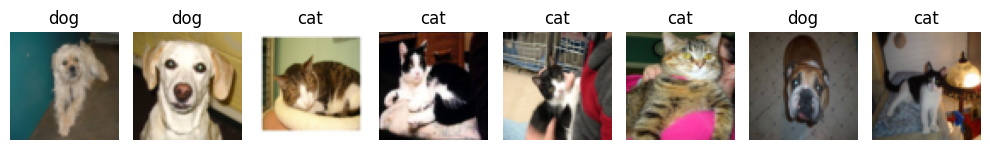

In [7]:
# Extract features/images and targets/labels
dataset_train = CatDogDataset(annotations_file='annotations_train.csv')
dataset_val = CatDogDataset(annotations_file='annotations_val.csv')

# Create data loaders
batch_size = 128
dataloader_train = DataLoader(dataset_train, batch_size=batch_size, shuffle=True)  # large batch size to get all data in one batch
dataloader_val = DataLoader(dataset_val, batch_size=10000, shuffle=False)
# Extract a batch of data from dataloaders
sample_batch_train = next(iter(dataloader_train))
sample_batch_val = next(iter(dataloader_val))

# Probe the data
print(f"training features batch shape: {sample_batch_train['image'].shape}, a sample features:\n {sample_batch_train['image'][0]}")
print(f"training labels batch shape: {sample_batch_train['category'].shape}, a sample label: {sample_batch_train['category'][0]}")
print(f"validation features batch shape: {sample_batch_val['image'].shape}, a sample features:\n {sample_batch_val['image'][0]}")
print(f"validation labels batch shape: {sample_batch_val['category'].shape}, a sample label: {sample_batch_val['category'][0]}")    

# Visualize a few sample images
fig, axs = plt.subplots(1, 8, figsize=(10, 5))
for i in range(8):
    sample_img = np.transpose(sample_batch_train['image'][i].reshape(3, 64, 64), (1, 2, 0))  # reconstruct image to (H, W, C) format
    sample_cls = sample_batch_train['category'][i]
    axs[i] = plt.subplot(1, 8, i + 1)
    axs[i].set_title(f'{"cat" if sample_cls == 1. else "dog"}')
    axs[i].axis('off')
    axs[i].imshow(sample_img)  # image is already in (H, W, C) format
plt.tight_layout()

# Rerun this cell to get different samples.

## 2. Multi-Layer Perceptron Model

A general feature transformation from a previous layer $[l-1]$ to the next layer $[l]$ can be defined as:

$$\mathbf{X}^{[l]} = \sigma (\mathbf{Z}^{[l]}) = \sigma (\mathbf{X}^{[l-1]} \cdot \mathbf{W}^{[l]T} + \mathbf{b}^{[l]}) $$

where $\mathbf{X}^{[l-1]}$ is the input features matrix from layer $[l-1]$. $\mathbf{Z}^{[l]}$ is the linearly transformed $\mathbf{X}^{[l-1]}$ with weight matrix, $\mathbf{W}^{[l]}$ and bias vector, $\mathbf{b}^{[l]}$. $\mathbf{X}^{[l]}$ is the output features matrix for layer $[l]$, which is $\mathbf{Z}^{[l]}$ activated by sigmoid function $\sigma (\cdot)$. 

In [11]:
def sigmoid(z):
    """ Sigmoid function
    Args:
        z: independent variable, could be an arrary of any shape or a scalar. 
    Returns:
        dependent variable, could be an arrary of any shape or a scalar. 
    """
    return 1 / (1 + np.exp(-z))

def linear(in_features, weights, biases):
    """ Linear function
    Args:
        in_features: input feature matrix, 2d array with shape (# samples, # input features)
        weights: weight parameter matrix, 2d array with shape (# next layer features , # input features)
        biases: bias parameter vector, 2d array with shape (1, # next layer features)
    Returns:
        linear_output: linear model output feature matrix, 2d array with shape (# samples, # next layer features)
    """
    out_features = in_features @ weights.T + biases
    return out_features

def forward(in_features, params):
    """ Forward function
    Args:
        in_features: feature matrix, 2d array with shape (# samples, # pixels)
        params: a dictionary of weights and biases
            params = {
                'W_1': weight matrix of the first layer, 2d array with shape (# hidden features in 1st layer, # input features)
                'b_1': bias vector of the first layer, 2d array with shape (1, # hidden features in 1st layer)
                ...
                'W_L': weight matrix of the last layer, 2d array with shape (# hidden features in output layer, # hidden features in L-1 layer)
                'b_L': bias vector of the last layer, 2d array with shape (1, # output features)
            }
    Returns:
        predictions: predicted probabilities, a column vector or 2d array with shape (# samples, # output features)
        cache: storage for features
    """

    num_layers = len(params) // 2
    # Input layer
    cache = {'X0': in_features}
    # Hidden layers
    for i in range(num_layers - 1):
        cache[f'Z{i+1}'] = linear(cache[f'X{i}'], params[f'W{i+1}'], params[f'b{i+1}'])
        cache[f'X{i+1}'] = sigmoid(cache[f'Z{i+1}'])
    # Output layer
    cache[f'Z{num_layers}'] = linear(cache[f'X{num_layers-1}'], params[f'W{num_layers}'], params[f'b{num_layers}'])
    predictions = sigmoid(cache[f'Z{num_layers}'])

    return predictions, cache

# Sanity check
params_dummy = {
    'W1': np.random.randn(10, 12288) * 0.01,  # 10 hidden features in the first layer
    'b1': np.zeros((1, 10)),
    'W2': np.random.randn(1, 10) * 0.01,      # 1 output feature in the last layer
    'b2': np.zeros((1, 1))
}
preds_dummy, cache_dummy = forward(sample_batch_val['image'].numpy(), params_dummy)
print(f"Dummy prediction:\n{preds_dummy}, shape: {preds_dummy.shape}")




Dummy prediction:
[[0.49987511]
 [0.4991762 ]
 [0.49933276]
 ...
 [0.4992079 ]
 [0.50016496]
 [0.49964208]], shape: (2023, 1)


### 2.1. Parameter Initialization


In [13]:
def init_params(in_dims, hidden_dims):
    """
    Initialize the parameters of the MLP model.
    Args:
        in_dims: number of input dimensions.
        hidden_dims: tuple of hidden layer dimensions.
    Returns:
        params: dictionary containing the initialized weights and biases.
    """
    layer_dims = (in_dims, *hidden_dims, 1)
    params = {}
    for l in range(len(layer_dims) - 1):
        params[f'W{l+1}'] = np.random.normal(loc=0, scale=0.1, size=(layer_dims[l + 1], layer_dims[l]))
        params[f'b{l+1}'] = np.random.normal(loc=0, scale=0.0001, size=(1, layer_dims[l + 1]))
    return params

# Example usage
params_dummy = init_params(in_dims=sample_batch_train['image'].shape[1], hidden_dims=(4, 3))
for key in params_dummy:
    print(f"{key}: value: \n{params_dummy[key]}, shape: {params_dummy[key].shape}")



W1: value: 
[[ 0.02322254  0.16260551  0.12928359 ...  0.1692701   0.0722534
   0.18860648]
 [-0.1215071  -0.00690621 -0.02755647 ... -0.09518721 -0.2414947
  -0.09045741]
 [ 0.09140269  0.01056383 -0.00210584 ... -0.01541417 -0.01288988
  -0.08251657]
 [-0.27039495  0.07402331  0.00883093 ...  0.00987163 -0.00253953
  -0.06586923]], shape: (4, 12288)
b1: value: 
[[ 1.53731193e-04 -4.55642187e-05  4.03142368e-05  1.71585249e-06]], shape: (1, 4)
W2: value: 
[[ 0.01406029  0.01520875 -0.07526614  0.08232256]
 [-0.03036506 -0.08797364  0.07144956 -0.02772291]
 [ 0.03359766  0.02593491  0.12612699  0.03173901]], shape: (3, 4)
b2: value: 
[[-5.20738008e-06 -1.78508981e-04  1.30985379e-04]], shape: (1, 3)
W3: value: 
[[ 0.02215022 -0.01985612  0.2648552 ]], shape: (1, 3)
b3: value: 
[[7.99049447e-05]], shape: (1, 1)


## 3. Model Evaluation

### 3.1. Binary Cross Entropy Loss
The CE function is more appropriate in classification tasks.
$$
\mathcal{L}(\hat{\mathbf{y}}, \mathbf{y}) = \frac{1}{M} \sum_{i=1}^{M} -{}^{(i)}y \ln {}^{(i)}\hat{y} - (1 - {}^{(i)}y) \ln (1 - {}^{(i)}\hat{y})
$$ 
$\mathbf{Y}$ is one-hot encoded label matrix.

### 3.2. Classification Metrics
#### 3.2.1. Accuracy
$$
A = \frac{TN + TP}{TN + TP + FN + FP}
$$

#### 3.2.2. Precision
$$
P = \frac{TP}{TP + FP}
$$

#### 3.2.3. Recall/Sensitivity
$$
A = \frac{TP}{TP + FN}
$$

In [15]:
def bce_loss(predictions, labels):
    """ Cross Entropy Loss
    Args:    return predictions, cache

    Returns:
    """
    sample_wise_losses = (-labels * np.log(predictions) - (1 - labels) * np.log(1 - predictions))
    return sample_wise_losses.mean()

def classify(predictions):
    pred_classes = np.zeros_like(predictions)
    pred_classes[predictions >= 0.5] = 1
    return pred_classes

def accuracy(predictions, labels):
    predicted_classes = classify(predictions)
    acc = np.mean((predicted_classes == labels))
    return acc

# Check functionalities
loss = bce_loss(preds_dummy, sample_batch_val['category'].numpy())
acc = accuracy(preds_dummy, sample_batch_val['category'].numpy())

print(f"Dummy model BCE loss: {bce_loss(preds_dummy, sample_batch_val['category'].numpy())}")
# print(f"True label samples: \n{sample_batch_val['category'].numpy()[:4]}")
print(f"Dummy classification samples: \n{classify(preds_dummy)[:10]}")
print(f"Dummy model accuracy: {accuracy(preds_dummy, sample_batch_val['category'].numpy()) * 100}%")


Dummy model BCE loss: 0.6931984579478188
Dummy classification samples: 
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [0.]
 [0.]]
Dummy model accuracy: 48.78892733564014%


## 4. Gradients of Loss

For $l$ from $L$ to 1:
$$
\frac{\partial \mathcal{L}}{\partial \mathbf{Z}^{[l]}} = \frac{\partial \mathcal{L}}{\partial \mathbf{X}^{[l]}} * a'(\mathbf{Z}^{[l]})
$$

$$
\frac{\partial \mathcal{L}}{\partial \mathbf{W}^{[l]}} = (\frac{\partial \mathcal{L}}{\partial \mathbf{Z}^{[l]}})^T \cdot \mathbf{X}^{[l-1]}
$$

$$
\frac{\partial \mathcal{L}}{\partial \mathbf{b}^{[l]}} = \text{mean}(\frac{\partial \mathcal{L}}{\partial \mathbf{Z}^{[l]}}, \text{axis}=0, \text{keepdims}) 
$$

$$
\frac{\partial \mathcal{L}}{\partial \mathbf{X}^{[l-1]}} = \frac{\partial \mathcal{L}}{\partial \mathbf{Z}^{[l]}} \cdot \mathbf{W}^{[l]}
$$

The special case for last layer:
$$
\frac{\partial \mathcal{L}}{\partial \mathbf{Z}^{[L]}} = \frac{\partial \mathcal{L}}{\partial \hat{\mathbf{Y}}} \cdot \frac{\partial \hat{\mathbf{Y}}}{\partial \mathbf{Z}^{[L]}} = \hat{\mathbf{Y}} - \mathbf{Y}
$$

In [66]:
def d_sigmoid(x):
    return sigmoid(x) * (1 - sigmoid(x))

def d_relu(x):
    return (x > 0).astype(float)

def backward(predictions, labels, cache, params, activation="relu"):
    num_layers = len(params) // 2
    grads = {f'dZ{num_layers}': predictions - labels}
    for i in reversed(range(num_layers)):
        grads[f'dW{i+1}'] = grads[f'dZ{i+1}'].T @ cache['X' + str(i)]
        grads[f'db{i+1}'] = np.mean(grads[f'dZ{i+1}'], axis=0, keepdims=True)
        if i==0:
            break  
        grads[f'dX{i}'] = grads[f'dZ{i+1}'] @ params[f'W{i+1}']
        if activation == 'relu':
            grads[f'dZ{i}'] = grads[f'dX{i}'] * d_relu(cache[f'Z{i}'])
        elif activation == 'sigmoid':
            grads[f'dZ{i}'] = grads[f'dX{i}'] * d_sigmoid(cache[f'Z{i}'])
        else:
            grads[f'dZ{i}'] = grads[f'dX{i}']

    return grads

grads_dummy = backward(preds_dummy, sample_batch_train['category'].numpy(), cache_dummy, params_dummy)
# print(grads_dummy)
for key in grads_dummy:
    print(f"{key}: shape {grads_dummy[key].shape}")


dZ3: shape (128, 2)
dW3: shape (2, 3)
db3: shape (1, 2)
dX2: shape (128, 3)
dZ2: shape (128, 3)
dW2: shape (3, 4)
db2: shape (1, 3)
dX1: shape (128, 4)
dZ1: shape (128, 4)
dW1: shape (4, 12288)
db1: shape (1, 4)


## 5. Gradient Descent

In [67]:
# Hyper-parameters
num_iters = 300
learning_rate = 1e-4
# Model parameters
params = init_params(in_dims=sample_batch_train['image'].numpy().shape[-1], hidden_dims=(32, 32), out_dims=2)
# Reserve metrics storage
losses_train, losses_val = [], []
accuracies_train, accuracies_val = [], []

# LOOP
for ep in range(num_iters):
    ep_loss, ep_acc = [], []
    for bi, batch_train in enumerate(dataloader_train):
        preds_train, cache_train = forward(batch_train['image'].numpy(), params, "relu", "softmax")
        batch_loss = ce_loss(preds_train, batch_train['category'].numpy())
        batch_acc = accuracy(preds_train, batch_train['category'].numpy())
        ep_loss.append(batch_loss)
        ep_acc.append(batch_acc)
        if not (bi+1) % 10:
            print(f"Training epoch {ep+1} batch {bi+1} loss: {batch_loss}, accuracy: {batch_acc}")
        grads = backward(preds_train, batch_train['category'].numpy(), cache_train, params, activation="relu")
        for l in range(len(params_dummy) // 2):
            params[f'W{l+1}'] = params[f'W{l+1}'] - learning_rate * grads[f'dW{l+1}']
            params[f'b{l+1}'] = params[f'b{l+1}'] - learning_rate * grads[f'db{l+1}']
    # Validate updated model on entire val dataset
    data_val = next(iter(dataloader_val))
    preds_val, _ = forward(data_val['image'].numpy(), params, "relu", "softmax")
    loss_val = ce_loss(preds_val, data_val['category'].numpy())
    acc_val = accuracy(preds_val, data_val['category'].numpy())
    print(f"Epoch {ep+1} validation accuracy: {acc_val}")    
    # Summarize epoch
    losses_train.append(np.mean(ep_loss))
    accuracies_train.append(np.mean(ep_acc))
    losses_val.append(loss_val)
    accuracies_val.append(acc_val)


Training epoch 1 batch 10 loss: 0.7102254962811971, accuracy: 0.46875
Training epoch 1 batch 20 loss: 0.6873757454632945, accuracy: 0.5546875
Training epoch 1 batch 30 loss: 0.687980437668223, accuracy: 0.5390625
Training epoch 1 batch 40 loss: 0.6524823780774431, accuracy: 0.6328125
Training epoch 1 batch 50 loss: 0.6888810262365823, accuracy: 0.5859375
Training epoch 1 batch 60 loss: 0.7002985373790671, accuracy: 0.5703125
Epoch 1 validation accuracy: 0.5205140879881365
Training epoch 2 batch 10 loss: 0.6887647562419166, accuracy: 0.5625
Training epoch 2 batch 20 loss: 0.6892855964898688, accuracy: 0.546875
Training epoch 2 batch 30 loss: 0.7023693585323739, accuracy: 0.5
Training epoch 2 batch 40 loss: 0.6816225054257752, accuracy: 0.5859375
Training epoch 2 batch 50 loss: 0.6921679264185052, accuracy: 0.5234375
Training epoch 2 batch 60 loss: 0.7002145459185458, accuracy: 0.46875
Epoch 2 validation accuracy: 0.5442412259021255
Training epoch 3 batch 10 loss: 0.6755224810150298, acc

(0.0, 1.0)

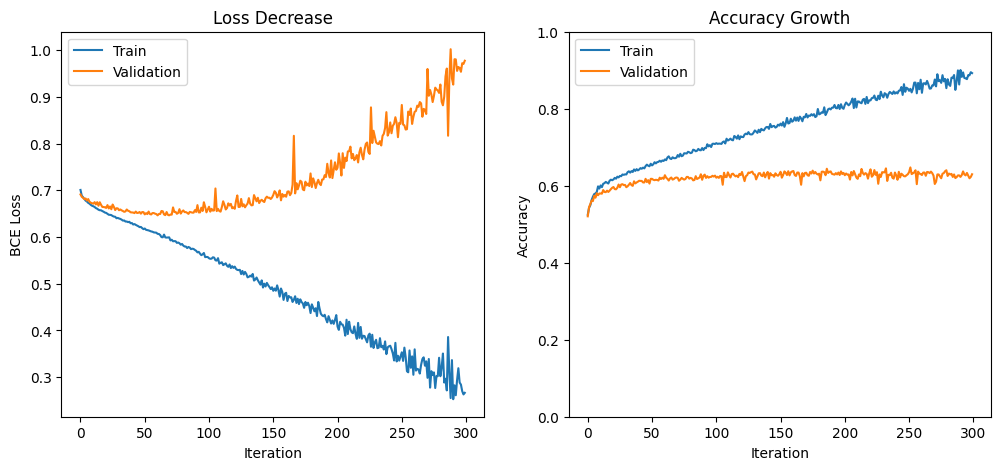

In [68]:
# Plot loss and accuracy curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(num_iters), losses_train, range(num_iters), losses_val)
plt.legend(['Train', 'Validation'])
plt.title("Loss Decrease")
plt.xlabel("Iteration")
plt.ylabel("BCE Loss")
plt.subplot(1, 2, 2)
plt.plot(range(num_iters), accuracies_train, range(num_iters), accuracies_val)
plt.legend(['Train', 'Validation'])
plt.title("Accuracy Growth")
plt.xlabel("Iteration")
plt.ylabel("Accuracy")
plt.ylim(0, 1)



Text(0.5, 1.0, 'Confusion Matrix - Validation Data')

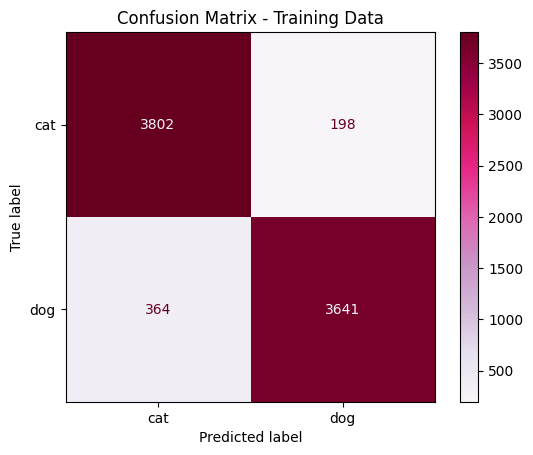

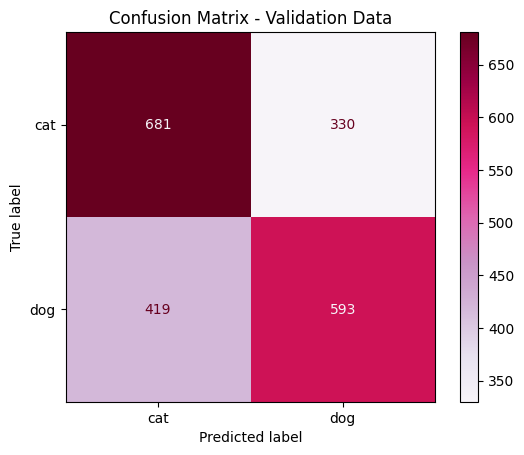

In [69]:
# Confusion Matrix for Test Data
dloader_train_all = DataLoader(dataset_train, batch_size=10000, shuffle=False)  # large batch size to get all data in one batch
data_train_all = next(iter(dloader_train_all))
labels_train_all = data_train_all['category'].numpy().argmax(axis=-1)
preds_train_all, _ = forward(data_train_all['image'].numpy(), params, "relu", "softmax")
predcls_train_all = preds_train_all.argmax(axis=-1)
# print(predcls_train_all)
# print(labels_train_all)
predcls_val_all = preds_val.argmax(axis=-1)
labels_val_all = data_val['category'].numpy().argmax(axis=-1)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm_train = confusion_matrix(labels_train_all, predcls_train_all)
disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=["cat", "dog"])
disp_train.plot(cmap='PuRd')
plt.title('Confusion Matrix - Training Data')
cm_val = confusion_matrix(labels_val_all, predcls_val_all)
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=["cat", "dog"])
disp_test.plot(cmap='PuRd')
plt.title('Confusion Matrix - Validation Data')

## 6. Test on New Images

In [70]:
test_dir = "./test_images"  # locate dataset directory from this repo in the whole system
test_cat_dir = Path(test_dir) / "cats"
test_dog_dir = Path(test_dir) / "dogs"


# Glob test files
test_cat_files = list(test_cat_dir.glob("**/*"))
test_dog_files = list(test_dog_dir.glob("**/*"))
test_files = test_cat_files + test_dog_files

for test_file in test_files:
    image_tensor = decode_image(test_file, mode=ImageReadMode.RGB)
    image = Resize((64, 64))(image_tensor)  # resize image to correct size
    image_np = image.numpy()  # convert image tensor to numpy array
    image_flatten = image_np.reshape(1, -1) / 255.  # rescale and reshape
    cat_dog_likelihood, _ = forward(image_flatten, params, "relu", "softmax")  # use model to predict
    is_dog = cat_dog_likelihood.argmax()
    if is_dog.squeeze():
        print(f"{test_file.name}: Woof!") 
    else:
        print(f"{test_file.name}: Meow!")

persian.jpg: Meow!
bengal_tiger.jpg: Woof!
garfield.png: Woof!
tabby.jpg: Woof!
basset.jpg: Woof!
kodiak_bear.jpg: Woof!
snoopy.png: Woof!
bernese.png: Woof!
